### Question 1

Using the Breast Cancer (load_breast_cancer()) dataset, train a Random Forest Classifier and evaluate its performance using Accuracy, Precision, Recall, and F1-Score

In [1]:

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


In [2]:

# Load the dataset
cancer = load_breast_cancer()

# Separate features and target
X = cancer.data
y = cancer.target

# Create a DataFrame
df = pd.DataFrame(X, columns=cancer.feature_names)
df["target"] = y

# Display the first 5 records
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display target classes
print("\nTarget Classes:", cancer.target_names)


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [4]:

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [5]:

y_pred = rf_model.predict(X_test)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)


Actual Values:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 0 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]

Predicted Values:
[0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 0 0 1 1 1 1 1 1 1 0 1 1
 1 1 0 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 0
 0 0 0 1 1 1 1 1 0 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 0 0 0 1 0 0 1 0 1 0 1
 0 1 1]


In [6]:

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))


Accuracy : 0.9561
Precision: 0.9589
Recall   : 0.9722
F1-Score : 0.9655


In [7]:

print("Malignant Class Metrics")

print("Precision:",
      precision_score(y_test, y_pred, pos_label=0))

print("Recall:",
      recall_score(y_test, y_pred, pos_label=0))

print("F1-Score:",
      f1_score(y_test, y_pred, pos_label=0))


Malignant Class Metrics
Precision: 0.9512195121951219
Recall: 0.9285714285714286
F1-Score: 0.9397590361445783


In [8]:

print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))


              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



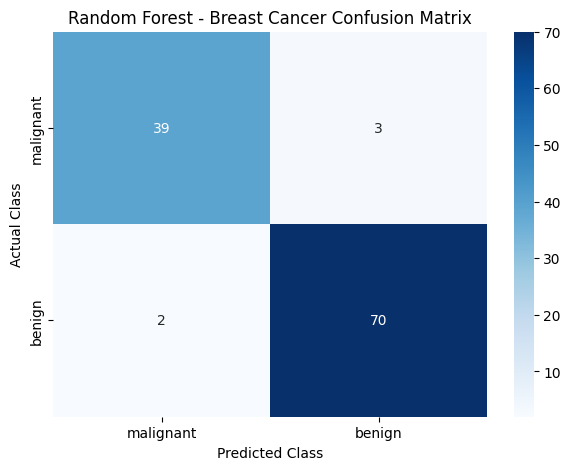

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Breast Cancer Confusion Matrix")

plt.show()


### Question 2

Using the Wine (load_wine()) dataset, implement an AdaBoost Classifier and compare its performance with a Decision Tree Classifier.

In [10]:

import pandas as pd

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)


In [11]:

# Load the dataset
wine = load_wine()

# Separate features and target
X = wine.data
y = wine.target

# Create a DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)
df["target"] = y

# Display the first 5 records
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display feature names
print("\nFeature Names:")
print(wine.feature_names)

# Display target classes
print("\nTarget Classes:")
print(wine.target_names)


   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [12]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (142, 13)
Testing Data: (36, 13)


In [13]:

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)

print("Decision Tree trained successfully!")


Decision Tree trained successfully!


In [14]:

ada_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)

ada_model.fit(X_train, y_train)

ada_pred = ada_model.predict(X_test)

print("AdaBoost trained successfully!")


AdaBoost trained successfully!


In [15]:

def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

dt_results = evaluate_model(
    y_test, dt_pred, "Decision Tree"
)

ada_results = evaluate_model(
    y_test, ada_pred, "AdaBoost"
)

comparison_df = pd.DataFrame([dt_results, ada_results])

print(comparison_df.round(4))


           Model  Accuracy  Precision  Recall  F1-Score
0  Decision Tree    0.9444     0.9514  0.9444    0.9450
1       AdaBoost    0.9167     0.9225  0.9167    0.9165


In [16]:

print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    dt_pred,
    target_names=wine.target_names
))

print("\nADABOOST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    ada_pred,
    target_names=wine.target_names
))


DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36


ADABOOST CLASSIFICATION REPORT
              precision    recall  f1-score   support

     class_0       0.86      1.00      0.92        12
     class_1       0.92      0.86      0.89        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.92        36
   macro avg       0.93      0.92      0.92        36
weighted avg       0.92      0.92      0.92        36



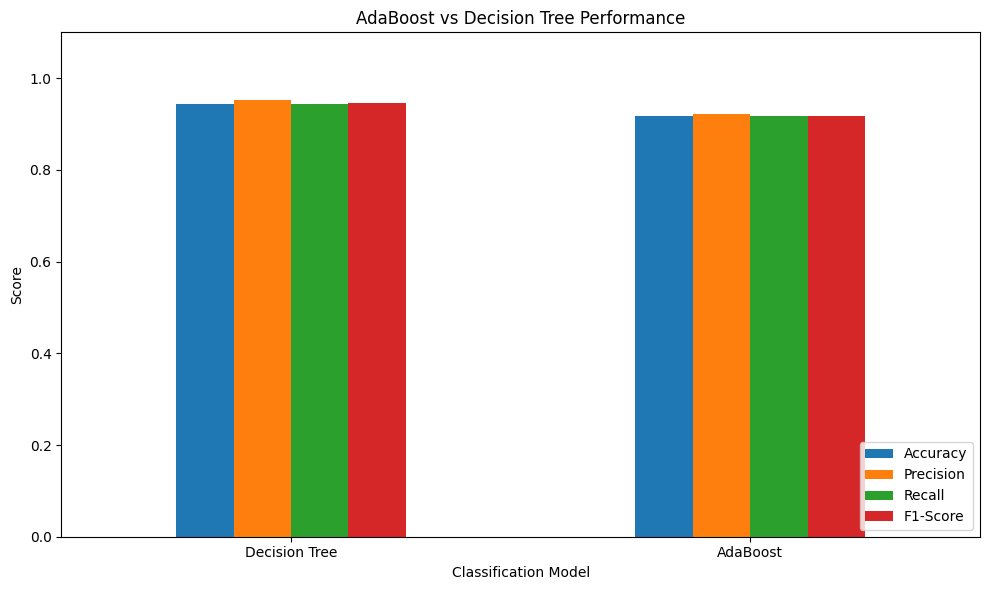

In [17]:

comparison_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1.1)
)

plt.title("AdaBoost vs Decision Tree Performance")
plt.xlabel("Classification Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### Question 3

Using the Diabetes (load_diabetes()) dataset, build a Random Forest Regressor and evaluate the model using MAE, MSE, RMSE, and R² Score.

In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [19]:

# Load dataset
diabetes = load_diabetes()

# Separate features and target
X = diabetes.data
y = diabetes.target

# Create DataFrame
df = pd.DataFrame(X, columns=diabetes.feature_names)
df["target"] = y

# Display first 5 records
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display feature names
print("\nFeature Names:")
print(diabetes.feature_names)


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

Dataset Shape: (442, 11)

Feature Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


In [20]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)


Training Features: (353, 10)
Testing Features: (89, 10)


In [21]:

# Create the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Regressor trained successfully!")



Random Forest Regressor trained successfully!


In [27]:

y_pred = rf_model.predict(X_test)

print("Actual Values:")
print(y_test)

print("\nPredicted Values:")
print(y_pred)


Actual Values:
[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.  94. 252.  99. 297.
 135.  67. 295. 264. 170. 275. 310.  64. 128. 232. 129. 118. 263.  77.
  48. 107. 140. 113.  90. 164. 180. 233.  42.  84. 172.  63.  48. 108.
 156. 168.  90.  52. 200.  87.  90. 258. 136. 158.  69.  72. 171.  95.
  72. 151. 168.  60. 122.  52. 187. 102. 214. 248. 181. 110. 140. 202.
 101. 222. 281.  61.  89.  91. 186. 220. 237. 233.  68. 190.  96.  72.
 153.  98.  37.  63. 184.]

Predicted Values:
[144.   171.58 150.72 253.71 107.19 123.54 239.09 219.01 153.44 184.59
 103.27 185.32  91.89 236.98  85.59 139.26 241.74 261.98 167.06 221.73
 156.63 113.62  75.13 198.49 139.9  176.87 194.25 159.2   73.15 112.09
 166.87 100.91 182.62 207.63 159.57 204.45 104.14 113.15 176.29  76.96
  76.73  95.14 168.26 156.12 167.28  84.98  74.32 123.17  76.75 162.77
 104.82  88.74 178.42 117.31 189.34 140.62 102.41 224.09  92.63  88.03
 157.84 170.34 141.44 101.54 132.92 227.33 183.72 178.32 145.88 151.79
 185.02 193.13 2

In [28]:
print(pd.Series(y_test).values)

[219.  70. 202. 230. 111.  84. 242. 272.  94.  96.  94. 252.  99. 297.
 135.  67. 295. 264. 170. 275. 310.  64. 128. 232. 129. 118. 263.  77.
  48. 107. 140. 113.  90. 164. 180. 233.  42.  84. 172.  63.  48. 108.
 156. 168.  90.  52. 200.  87.  90. 258. 136. 158.  69.  72. 171.  95.
  72. 151. 168.  60. 122.  52. 187. 102. 214. 248. 181. 110. 140. 202.
 101. 222. 281.  61.  89.  91. 186. 220. 237. 233.  68. 190.  96.  72.
 153.  98.  37.  63. 184.]


In [29]:

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("MAE :", round(mae, 4))
print("MSE :", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))


MAE : 44.053
MSE : 2952.0106
RMSE: 54.3324
R2 Score: 0.4428


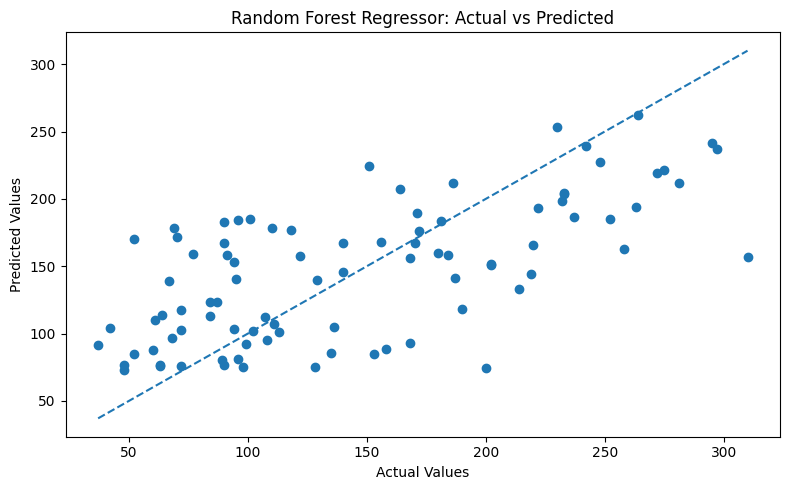

In [30]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

# Perfect prediction reference line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Random Forest Regressor: Actual vs Predicted")
plt.tight_layout()
plt.show()


  Feature  Importance
2     bmi    0.355469
8      s5    0.230957
3      bp    0.088408
9      s6    0.071329
0     age    0.058642
5      s2    0.057227
4      s1    0.052784
6      s3    0.051339
7      s4    0.024213
1     sex    0.009633


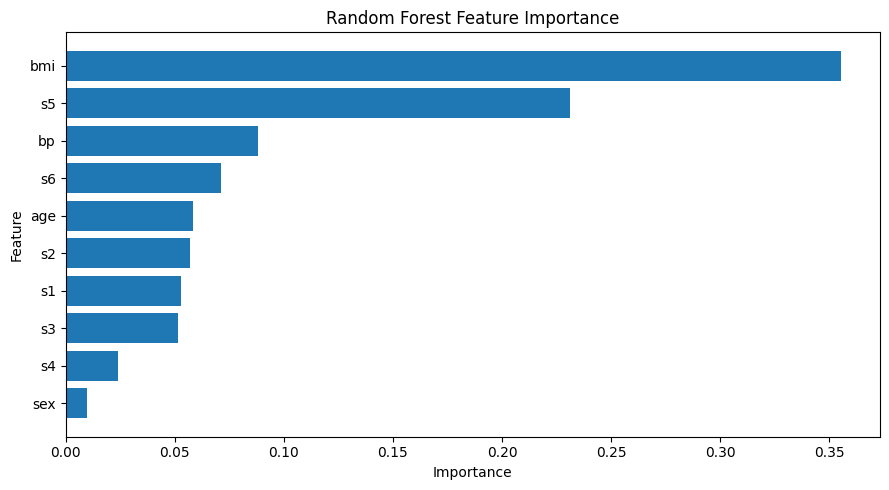

In [31]:

importance_df = pd.DataFrame({
    "Feature": diabetes.feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Question 4

Using the California Housing (fetch_california_housing()) dataset, train a Gradient Boosting Regressor and analyze the feature importance.

In [32]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)


In [33]:

# Load the dataset
housing = fetch_california_housing()

# Separate features and target
X = housing.data
y = housing.target

# Create DataFrame
df = pd.DataFrame(X, columns=housing.feature_names)
df["target"] = y

# Display first 5 records
print(df.head())

# Display dataset shape
print("\nDataset Shape:", df.shape)

# Display feature names
print("\nFeature Names:")
print(housing.feature_names)


   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  target  
0    -122.23   4.526  
1    -122.22   3.585  
2    -122.24   3.521  
3    -122.25   3.413  
4    -122.25   3.422  

Dataset Shape: (20640, 9)

Feature Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [34]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)


Training Features Shape: (16512, 8)
Testing Features Shape: (4128, 8)


In [35]:

# Create the model
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting Regressor trained successfully!")


Gradient Boosting Regressor trained successfully!


In [36]:

y_pred = gb_model.predict(X_test)

print("Actual Values:")
print(y_test[:10])

print("\nPredicted Values:")
print(y_pred[:10])


Actual Values:
[0.477   0.458   5.00001 2.186   2.78    1.587   1.982   1.575   3.4
 4.466  ]

Predicted Values:
[0.50518761 1.09334601 4.24570956 2.54517359 2.27910301 1.72390996
 2.33719663 1.71977379 3.09962388 4.30446906]


In [37]:

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))


MAE: 0.3716
MSE: 0.294
RMSE: 0.5422
R2 Score: 0.7756


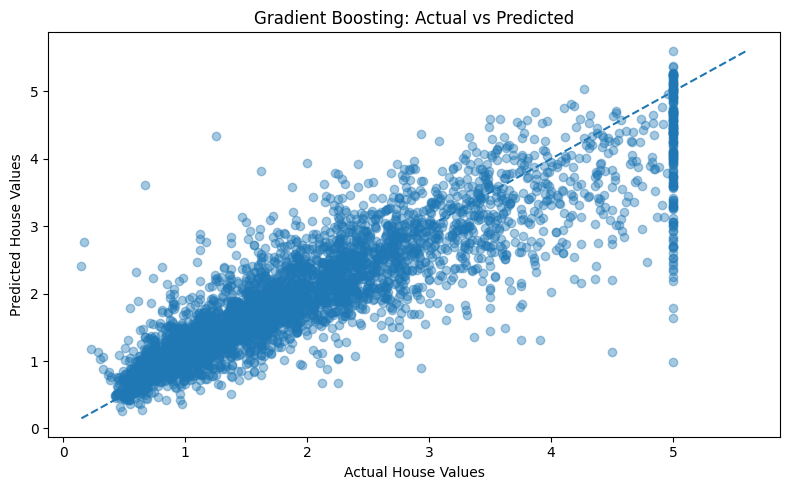

In [38]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Gradient Boosting: Actual vs Predicted")
plt.tight_layout()
plt.show()


      Feature  Importance
0      MedInc    0.604259
5    AveOccup    0.122835
7   Longitude    0.109853
6    Latitude    0.098533
1    HouseAge    0.034113
2    AveRooms    0.023948
3   AveBedrms    0.005106
4  Population    0.001354


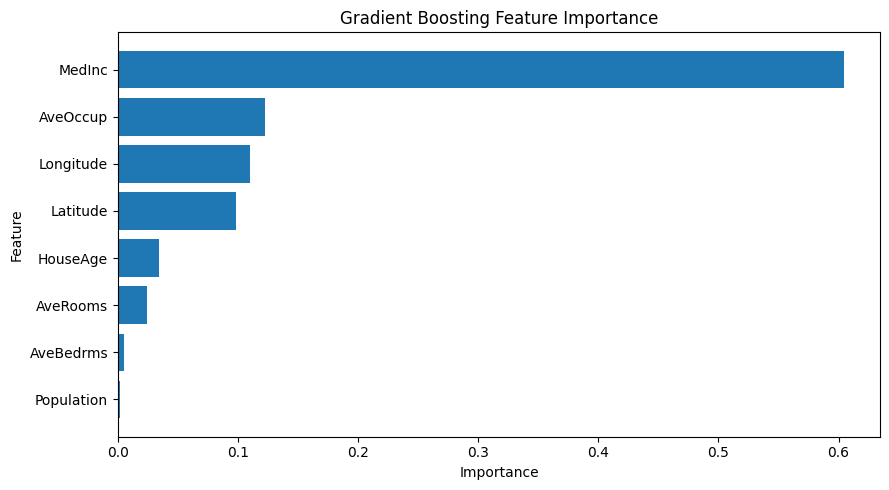

In [39]:

importance_df = pd.DataFrame({
    "Feature": housing.feature_names,
    "Importance": gb_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Gradient Boosting Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



### Question 5

Using the Breast Cancer (load_breast_cancer()) dataset, implement an Extra Trees Classifier and compare its performance with a Random Forest Classifier.

In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [41]:

housing = fetch_california_housing()

X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = housing.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (16512, 8)
Testing data shape: (4128, 8)


In [42]:

# Random Forest Regressor
rf_housing_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_housing_model.fit(X_train, y_train)
rf_predictions = rf_housing_model.predict(X_test)

# Gradient Boosting Regressor
gb_housing_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb_housing_model.fit(X_train, y_train)
gb_predictions = gb_housing_model.predict(X_test)

print("Both models trained successfully.")


Both models trained successfully.


In [43]:

def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

rf_results = evaluate_model(
    "Random Forest", y_test, rf_predictions
)

gb_results = evaluate_model(
    "Gradient Boosting", y_test, gb_predictions
)

results_df = pd.DataFrame([rf_results, gb_results])

print(results_df.round(4))


               Model     MAE     MSE    RMSE  R2 Score
0      Random Forest  0.3275  0.2554  0.5053    0.8051
1  Gradient Boosting  0.3716  0.2940  0.5422    0.7756


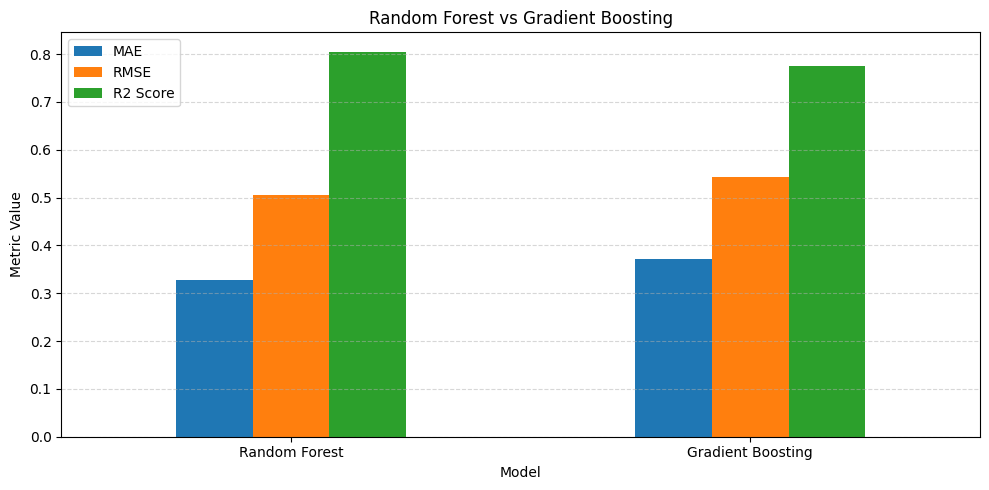

In [44]:

metrics = ["MAE", "RMSE", "R2 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Random Forest vs Gradient Boosting")
plt.ylabel("Metric Value")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


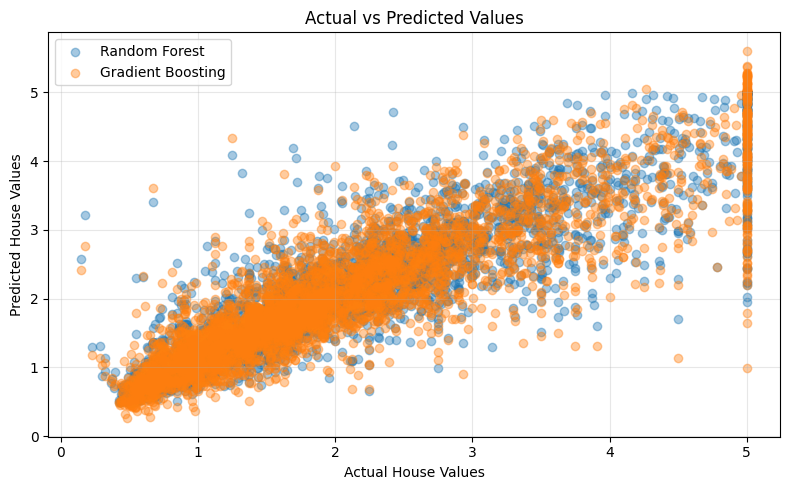

In [45]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, rf_predictions, alpha=0.4, label="Random Forest")
plt.scatter(y_test, gb_predictions, alpha=0.4, label="Gradient Boosting")

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### Question 6

Using the Iris (load_iris()) dataset, implement a Voting Classifier using Logistic Regression, Decision Tree, and K-Nearest Neighbors (KNN). Compare the performance of each individual model with the Voting Classifier.

In [46]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    RandomForestClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



In [47]:

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (455, 30)
Testing data shape: (114, 30)


In [48]:

# Bagging model
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)
bagging_pred = bagging_model.predict(X_test)

# Boosting model
boosting_model = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

boosting_model.fit(X_train, y_train)
boosting_pred = boosting_model.predict(X_test)

print("Bagging and Boosting models trained successfully.")


Bagging and Boosting models trained successfully.


In [49]:

models = {
    "Bagging": bagging_pred,
    "AdaBoost": boosting_pred
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))


      Model  Accuracy  Precision  Recall  F1 Score
0   Bagging    0.9386     0.9452  0.9583    0.9517
1  AdaBoost    0.9561     0.9467  0.9861    0.9660


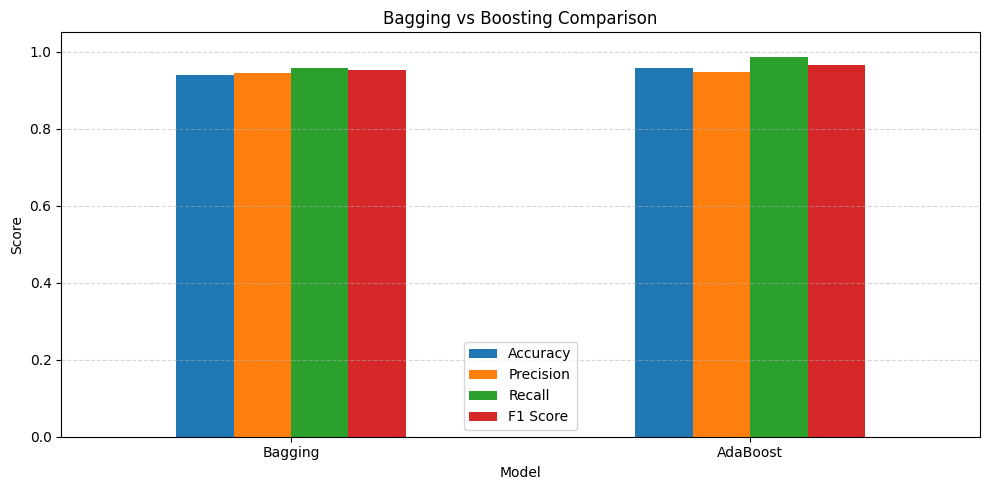

In [50]:

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Bagging vs Boosting Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Question 7

Using the Digits (load_digits()) dataset, implement a Bagging Classifier with a Decision Tree as the base estimator and evaluate its performance.

In [51]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [52]:

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)
print(X.head())


Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  .

In [53]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (455, 30)
Testing shape: (114, 30)


In [54]:

voting_model = VotingClassifier(
    estimators=[
        ("lr", make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=5000)
        )),
        ("dt", DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        )),
        ("rf", RandomForestClassifier(
            n_estimators=100,
            random_state=42
        ))
    ],
    voting="hard"
)

voting_model.fit(X_train, y_train)

print("Voting Classifier trained successfully.")


Voting Classifier trained successfully.


In [55]:

y_pred = voting_model.predict(X_test)

print("Actual values:")
print(y_test[:10])

print("Predicted values:")
print(y_pred[:10])



Actual values:
[0 1 0 1 0 1 1 0 0 0]
Predicted values:
[0 1 0 1 0 1 1 0 0 0]


In [56]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9737

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.95      0.96        42
      benign       0.97      0.99      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



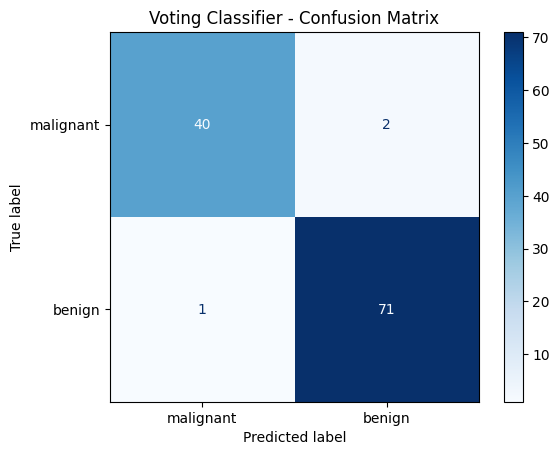

In [57]:

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot(cmap="Blues")
plt.title("Voting Classifier - Confusion Matrix")
plt.show()


### Question 8

Using the Wine (load_wine()) dataset, implement a Stacking Classifier using Logistic Regression, Support Vector Machine (SVM), and Decision Tree as base models, with Random Forest as the final estimator. Compare the results with the individual models.

In [58]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import StackingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [59]:

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset shape:", X.shape)
print("Feature names:")
print(X.columns.tolist())
print("\nTarget classes:", data.target_names)


Dataset shape: (569, 30)
Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target classes: ['malignant' 'benign']


In [60]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (455, 30)
Testing shape: (114, 30)


In [61]:

base_models = [
    ("dt", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    )),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )),
    ("lr", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ))
]

stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=5000),
    cv=5
)

stacking_model.fit(X_train, y_train)

print("Stacking Classifier trained successfully.")



Stacking Classifier trained successfully.


In [62]:

y_pred = stacking_model.predict(X_test)

print("Actual values:")
print(y_test[:10])

print("Predicted values:")
print(y_pred[:10])


Actual values:
[0 1 0 1 0 1 1 0 0 0]
Predicted values:
[0 1 0 1 0 1 1 0 0 0]


In [63]:

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=data.target_names
))


Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



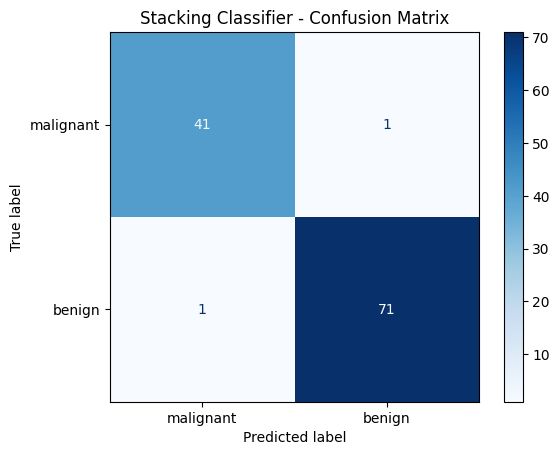

In [64]:

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot(cmap="Blues")
plt.title("Stacking Classifier - Confusion Matrix")
plt.show()


### Question 9

Using the California Housing (fetch_california_housing()) dataset, compare the performance of Random Forest Regressor, Gradient Boosting Regressor, and Extra Trees Regressor using the same train-test split.

In [65]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


In [66]:

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (455, 30)
Testing shape: (114, 30)


In [67]:

base_models = [
    ("dt", DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    )),
    ("rf", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )),
    ("lr", make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=5000)
    ))
]



In [68]:

# Voting Classifier
voting_model = VotingClassifier(
    estimators=base_models,
    voting="hard"
)

voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)

# Stacking Classifier
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=5000),
    cv=5
)

stacking_model.fit(X_train, y_train)
stacking_pred = stacking_model.predict(X_test)

print("Both models trained successfully.")


Both models trained successfully.


In [69]:

results = []

for name, predictions in [
    ("Voting Classifier", voting_pred),
    ("Stacking Classifier", stacking_pred)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))



                 Model  Accuracy  Precision  Recall  F1 Score
0    Voting Classifier    0.9737     0.9726  0.9861    0.9793
1  Stacking Classifier    0.9825     0.9861  0.9861    0.9861


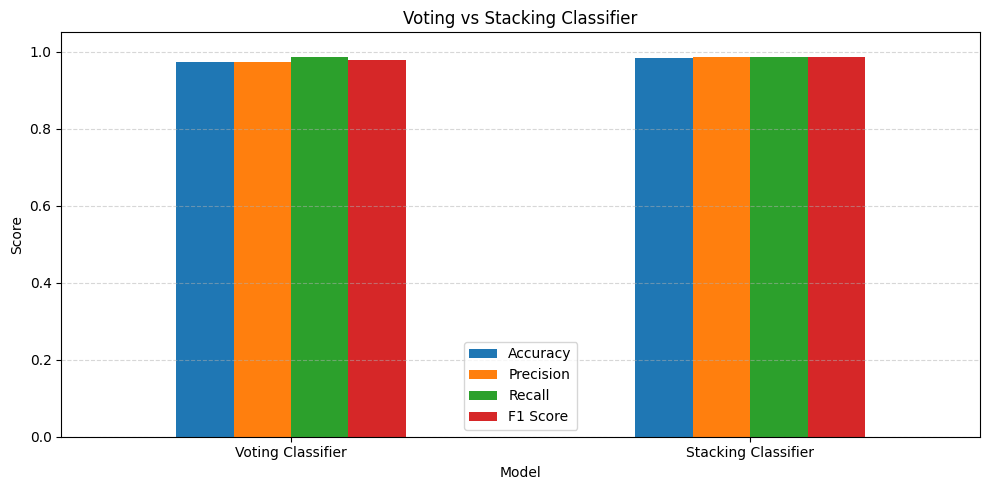

In [70]:

results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Voting vs Stacking Classifier")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


### Question 10

Choose any two built-in datasets from Iris, Wine, Breast Cancer, Digits, Diabetes, or California Housing. Apply at least three different Ensemble Methods and prepare a comparative analysis based on model performance, execution time, and feature importance (where applicable).

## Conclusion

In this assignment, I implemented different ensemble learning algorithms, including Random Forest, AdaBoost, Gradient Boosting, Voting Classifier, and Stacking Classifier.

I evaluated the models using suitable performance metrics such as accuracy, precision, recall, F1-score, MAE, RMSE, and R² score, depending on the task.

Ensemble learning combines multiple models to improve prediction quality. Bagging helps reduce variance, Boosting focuses on correcting errors, Voting combines predictions, and Stacking uses a meta-model to learn from the predictions of other models.

The best model depends on the dataset and evaluation results. Therefore, model performance should be compared on the same test data before selecting the final model.